<a href="https://colab.research.google.com/github/kunjana30/Internship-Project-2/blob/main/Task6_Business_Insights_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 6 (Advanced) – Netflix Business Insights Report

**Goal:** Create a comprehensive business-intelligence report from the Netflix dataset – the capstone that ties everything together.

**Prerequisite:** run the Task 1 notebook first (it creates `netflix_cleaned.csv`). This notebook is self-contained, so you do *not* need Tasks 2–5 first.

| Step | What we do | Output |
|------|-----------|--------|
| 1 | Perform complete exploratory data analysis (EDA) | EDA figure + tables |
| 2 | Identify key content trends and patterns | Trend scorecard, genre momentum |
| 3 | Develop multiple visual dashboards | 4 dashboard PNGs |
| 4 | Generate actionable business insights | Insight table (Finding → Evidence → Action) |
| 5 | Prepare and present the final analytical report | A self-contained **HTML report** |

> ⚠️ The dataset ends in **September 2021**, so 2021 is a *partial* year. It is flagged in charts and left out of growth comparisons where it would mislead.

### ☁️ Google Colab / Drive setup – run this cell first
Colab's storage is **temporary**: files in `/content` disappear when the session ends, and each notebook runs in its own session.
So this cell connects to your **Google Drive** and works inside a folder called `Netflix_Analysis`, keeping `Dataset.csv`,
`netflix_cleaned.csv` (created by Task 1) and all outputs in one permanent place.

* A pop-up will ask you to allow Drive access - choose your account and click **Allow**.
* Make sure `MyDrive/Netflix_Analysis/` contains `Dataset.csv` (and `netflix_cleaned.csv` once Task 1 has been run).
* **Running locally in Jupyter?** This cell does nothing outside Colab, so you can leave it as it is.
* **No Drive?** Set `USE_DRIVE = False` and upload the files with the Files panel (folder icon on the left). They are deleted when the runtime resets.

In [ ]:
import os, sys

USE_DRIVE = True                                          # set to False to skip Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Netflix_Analysis"   # the folder in your Drive that holds the project files

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)

print("Working folder:", os.getcwd())
print("Files here    :", sorted(os.listdir(".")))

---
## Step 0 – Setup and load

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown
import base64
import calendar
import html as html_lib
from IPython.display import HTML
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.grid.axis": "y"})
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# Netflix-inspired colours used consistently across every chart
NETFLIX_RED, NETFLIX_DARK, GREY = "#E50914", "#221F1F", "#B3B3B3"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": NETFLIX_DARK}

CLEAN_PATH = Path("netflix_cleaned.csv")          # created by Task 1
OUT_DIR = Path("outputs/task6_business_report")                   # charts & tables are saved here (for your screenshots/report)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into the task's output folder."""
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

if not CLEAN_PATH.exists():
    raise FileNotFoundError("'netflix_cleaned.csv' not found. Run the Task 1 notebook first and keep this notebook in the same folder.")

In [ ]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])
print(f"Loaded {len(df):,} titles x {df.shape[1]} columns")
df.head()

---
## Step 1 – Perform complete exploratory data analysis (EDA)
### 1a. Dataset overview and helper tables
We prepare the building blocks (exploded genres, known-country subset, yearly counts) used throughout the notebook.

In [ ]:
GROUP_ORDER = ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]
GROUP_COLORS = {"Kids": "#2E86AB", "Older Kids": "#7FB7BE", "Teens": "#F6AE2D", "Adults": NETFLIX_RED, "Not Rated": "#B3B3B3"}

PARTIAL_YEAR = int(df["date_added"].max().year)          # data stops in Sept of this year
LAST_COMPLETE = PARTIAL_YEAR - 1

df["lag_years"] = (df["year_added"] - df["release_year"]).clip(lower=0)      # years between release and arrival on Netflix

movies = df[df["type"] == "Movie"].copy()
movies["duration_min"] = movies["duration_min"].astype(float)
known_country = df[df["country"] != "Unknown"]

genres = df.assign(genre=df["listed_in"].str.split(",")).explode("genre").reset_index(drop=True)
genres["genre"] = genres["genre"].str.strip()

genre_counts = genres["genre"].value_counts().rename_axis("genre").reset_index(name="titles")
country_counts = known_country["country"].value_counts().rename_axis("country").reset_index(name="titles")
country_counts["share_%"] = country_counts["titles"] / country_counts["titles"].sum() * 100

yearly = (df.pivot_table(index="release_year", columns="type", values="show_id", aggfunc="count", fill_value=0)
            .reindex(range(int(df["release_year"].min()), int(df["release_year"].max()) + 1), fill_value=0))
yearly["Total"] = yearly["Movie"] + yearly["TV Show"]
peak_year = int(yearly["Total"].idxmax())

# ---- headline KPIs (reused in the dashboards and the final report) ----
kpis = [
    (f"{len(df):,}", "titles in the catalogue"),
    (f"{(df['type'] == 'Movie').mean():.0%} / {(df['type'] == 'TV Show').mean():.0%}", "Movies / TV Shows"),
    (f"{known_country['country'].nunique()}", "countries represented"),
    (f"{country_counts['share_%'].iloc[0]:.0f}%", f"from the {country_counts['country'].iloc[0]}"),
    (f"{(df['rating_group'] == 'Adults').mean():.0%}", "rated for adults"),
    (f"{(df['release_year'] >= 2015).mean():.0%}", "released since 2015"),
]

print(f"Period covered (date added): {df['date_added'].min().date()} -> {df['date_added'].max().date()}")
print(f"Release years: {df['release_year'].min()} -> {df['release_year'].max()}   |   {genres['genre'].nunique()} distinct genre tags")
pd.DataFrame(kpis, columns=["value", "metric"])

### 1b. Data quality recap and summary statistics

In [ ]:
unknown_director = (df["director"] == "Unknown").mean() * 100
unknown_country = (df["country"] == "Unknown").mean() * 100
print(f"Unknown director: {unknown_director:.1f}% of titles | Unknown country: {unknown_country:.1f}% of titles")
print("(the other columns have no missing values after Task 1)\n")

num_cols = ["release_year", "year_added", "lag_years", "duration_min", "seasons", "n_genres"]
df[num_cols].astype(float).describe().T.round(1)

In [ ]:
# Categorical columns: the 5 most common values of each
for col in ["type", "rating", "country", "primary_genre"]:
    top = df[col].value_counts().head(5)
    print(f"{col:14s}", " | ".join(f"{k}: {v:,}" for k, v in top.items()))

### 1c. Outlier check – are unusual runtimes errors?
We use the **IQR rule**: values more than 1.5 × IQR beyond the quartiles are flagged.

In [ ]:
q1, q3 = movies["duration_min"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = movies[(movies["duration_min"] < low) | (movies["duration_min"] > high)]

print(f"Typical runtime range: {low:.0f}-{high:.0f} min  |  flagged: {len(outliers)} of {len(movies):,} movies ({len(outliers) / len(movies):.1%})")
print("\nLongest:");  print(movies.nlargest(3, "duration_min")[["title", "duration_min"]].to_string(index=False))
print("\nShortest:"); print(movies.nsmallest(3, "duration_min")[["title", "duration_min"]].to_string(index=False))

These are **not errors** – they are genuinely long films/interactive specials and very short films/shorts. We **keep them**, but use the **median** (robust to outliers) instead of the mean when summarising runtime.

### 1d. EDA figure – distributions and relationships

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# (a) release years
axes[0, 0].hist(df.loc[df["release_year"] >= 1990, "release_year"], bins=range(1990, 2023), color=NETFLIX_RED, edgecolor="white")
axes[0, 0].set_title("Release year (1990 onwards)"); axes[0, 0].set_xlabel("Release year"); axes[0, 0].set_ylabel("Titles")

# (b) additions per year by type
added_type = pd.crosstab(df["year_added"], df["type"])[["Movie", "TV Show"]].loc[2013:]
added_type.plot(kind="bar", stacked=True, ax=axes[0, 1], color=[TYPE_COLORS["Movie"], TYPE_COLORS["TV Show"]], width=0.75)
axes[0, 1].set_title(f"Titles added per year ({PARTIAL_YEAR} = Jan-Sep)"); axes[0, 1].set_xlabel("Year added"); axes[0, 1].set_ylabel("Titles")
axes[0, 1].tick_params(axis="x", rotation=45); axes[0, 1].legend(frameon=False, title=""); axes[0, 1].grid(axis="x", visible=False)

# (c) runtime by audience group
sns.boxplot(data=movies, x="rating_group", y="duration_min", order=GROUP_ORDER, color=NETFLIX_RED, fliersize=2, ax=axes[0, 2])
axes[0, 2].set_title("Movie runtime by audience group"); axes[0, 2].set_xlabel(""); axes[0, 2].set_ylabel("Minutes")
axes[0, 2].tick_params(axis="x", rotation=20)

# (d) seasons
seasons = df.loc[df["type"] == "TV Show", "seasons"].astype(float).clip(upper=6).value_counts().sort_index()
axes[1, 0].bar([str(int(s)) if s < 6 else "6+" for s in seasons.index], seasons.values, color=NETFLIX_DARK)
axes[1, 0].set_title("TV shows by number of seasons"); axes[1, 0].set_xlabel("Seasons"); axes[1, 0].set_ylabel("TV shows")

# (e) genre tags per title
ng = df["n_genres"].value_counts().sort_index()
b = axes[1, 1].bar(ng.index.astype(str), ng.values, color=NETFLIX_RED)
axes[1, 1].bar_label(b, labels=[f"{v / len(df):.0%}" for v in ng.values], padding=3)
axes[1, 1].set_title("Genre tags per title"); axes[1, 1].set_xlabel("Number of genre tags"); axes[1, 1].set_ylabel("Titles")

# (f) correlation
corr = df[["release_year", "year_added", "lag_years", "duration_min", "n_genres"]].astype(float).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False, ax=axes[1, 2])
axes[1, 2].set_title("Correlation between numeric features"); axes[1, 2].tick_params(axis="x", rotation=30)

fig.suptitle("Exploratory data analysis", fontsize=19, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.965]); save_fig("00_eda_overview"); plt.show()

**Reading the correlation panel:** `release_year` and `lag_years` correlate at about **-0.98** – but that is *by construction*
(`lag_years = year_added - release_year`), so it tells us nothing new. The one genuinely interesting link is a moderate positive
relationship between runtime and the number of genre tags (longer films carry more tags; note that no title in this file has more than 3 tags). Always ask *"is this correlation mechanical?"* before interpreting it, and remember **correlation ≠ causation**.

---
## Step 2 – Identify key content trends and patterns
We compare two periods of **when titles were added** to see how the catalogue strategy changed:
**Early = 2016-2018** vs **Recent = 2019 to Sept 2021**.

In [ ]:
EARLY, RECENT = (2016, 2018), (2019, PARTIAL_YEAR)
early = df[df["year_added"].between(*EARLY)]
recent = df[df["year_added"].between(*RECENT)]
months_early = 12 * (EARLY[1] - EARLY[0] + 1)
months_recent = 12 * (RECENT[1] - RECENT[0]) + int(df["date_added"].max().month)     # last year only counts Jan-Sep

def window_metrics(f, n_months):
    k = f[f["country"] != "Unknown"]
    return pd.Series({
        "Titles added per month": len(f) / n_months,
        "TV Show share (%)": (f["type"] == "TV Show").mean() * 100,
        "US share of known-country titles (%)": (k["country"] == "United States").mean() * 100,
        "India share of known-country titles (%)": (k["country"] == "India").mean() * 100,
        "Adult-rated share (%)": (f["rating_group"] == "Adults").mean() * 100,
        "Kids + Older Kids share (%)": f["rating_group"].isin(["Kids", "Older Kids"]).mean() * 100,
        "Median movie runtime (min)": f["duration_min"].astype(float).median(),
        "Arrived within 1 year of release (%)": (f["lag_years"] <= 1).mean() * 100,
        "Genre tags per title": f["n_genres"].mean(),
    })

early_label, recent_label = f"{EARLY[0]}-{EARLY[1]}", f"{RECENT[0]}-{str(RECENT[1])[2:]} (YTD)"
scorecard = pd.DataFrame({early_label: window_metrics(early, months_early), recent_label: window_metrics(recent, months_recent)})
scorecard["change"] = scorecard[recent_label] - scorecard[early_label]
scorecard["change_%"] = scorecard["change"] / scorecard[early_label] * 100
scorecard = scorecard.round(1)
scorecard.to_csv(OUT_DIR / "trend_scorecard.csv")
scorecard

### Genre momentum – which genres are gaining or losing share?
We compare each genre's **share of titles added** in the two periods (percentage-point change), keeping only genres with at least 150 titles so tiny categories don't distort the picture.

In [ ]:
g_early = genres[genres["year_added"].between(*EARLY)]["genre"].value_counts()
g_recent = genres[genres["year_added"].between(*RECENT)]["genre"].value_counts()

momentum = pd.DataFrame({
    "early_%": g_early / len(early) * 100,
    "recent_%": g_recent / len(recent) * 100,
    "titles": g_early.add(g_recent, fill_value=0),
}).fillna(0)
momentum["change_pp"] = momentum["recent_%"] - momentum["early_%"]
momentum = momentum[momentum["titles"] >= 150].sort_values("change_pp").round(1)
momentum.to_csv(OUT_DIR / "genre_momentum.csv")

print("Biggest gainers:"); print(momentum.tail(5).iloc[::-1][["early_%", "recent_%", "change_pp"]])
print("\nBiggest decliners:"); print(momentum.head(5)[["early_%", "recent_%", "change_pp"]])

### Geography, audience and seasonality over time

In [ ]:
# Country mix of additions per year (top-5 countries)
top5 = country_counts["country"].head(5).tolist()
country_share = (pd.crosstab(known_country["year_added"], known_country["country"], normalize="index")[top5] * 100).loc[2016:]

# Audience mix by release year (complete years)
mix_pct = (pd.crosstab(df["release_year"], df["rating_group"], normalize="index")[GROUP_ORDER] * 100).loc[2008:LAST_COMPLETE]

# Seasonality: titles added per calendar month, complete years only
month_totals = df[df["year_added"].between(2016, LAST_COMPLETE)].groupby("month_added").size()
season = (df[df["year_added"] >= 2015]
          .pivot_table(index="month_added", columns="year_added", values="show_id", aggfunc="count", fill_value=0)
          .reindex(range(1, 13), fill_value=0).astype(float))
season.loc[season.index > df["date_added"].max().month, PARTIAL_YEAR] = np.nan      # months that have not happened yet: blank, not zero
season.index = [calendar.month_abbr[i] for i in season.index]

print("US share of additions by year:", country_share["United States"].round(0).astype(int).to_dict())
print("Busiest months:", [calendar.month_name[m] for m in month_totals.sort_values(ascending=False).head(3).index])
print("Quietest months:", [calendar.month_name[m] for m in month_totals.sort_values().head(3).index])

---
## Step 3 – Develop multiple visual dashboards
Four themed dashboards, each a multi-panel figure saved as a PNG (these feed the final report and your screenshots).

### Dashboard 1 – Catalogue overview

In [ ]:
def finish_dashboard(fig, title, name):
    fig.suptitle(title, fontsize=20, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    save_fig(name)
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Movies vs TV donut
tc = df["type"].value_counts().reindex(["Movie", "TV Show"])
_, _, autotexts = axes[0, 0].pie(tc, labels=tc.index, colors=[TYPE_COLORS[t] for t in tc.index], autopct="%1.0f%%", startangle=90,
                                 pctdistance=0.78, wedgeprops=dict(width=0.42, edgecolor="white"), textprops={"fontsize": 12})
for t in autotexts: t.set_color("white"); t.set_fontweight("bold")
axes[0, 0].set_title("Movies vs TV Shows")

# Audience
ga = df["rating_group"].value_counts().reindex(GROUP_ORDER)
b = axes[0, 1].bar(GROUP_ORDER, ga.values, color=[GROUP_COLORS[g] for g in GROUP_ORDER])
axes[0, 1].bar_label(b, labels=[f"{v / len(df):.0%}" for v in ga.values], padding=3)
axes[0, 1].set_title("Target audience"); axes[0, 1].tick_params(axis="x", rotation=20); axes[0, 1].set_ylabel("Titles"); axes[0, 1].set_ylim(0, ga.max() * 1.12)

# Release years
yr = yearly.loc[2000:]
axes[0, 2].fill_between(yr.index, yr["Total"], color=NETFLIX_RED, alpha=0.9)
axes[0, 2].axvspan(PARTIAL_YEAR - 0.5, PARTIAL_YEAR + 0.5, color=GREY, alpha=0.35)
axes[0, 2].set_title(f"Titles by release year (peak: {peak_year})"); axes[0, 2].set_ylabel("Titles"); axes[0, 2].set_ylim(bottom=0)

# Top genres
tg = genre_counts.head(10).iloc[::-1]
axes[1, 0].barh(tg["genre"], tg["titles"], color=NETFLIX_DARK); axes[1, 0].set_title("Top 10 genre tags"); axes[1, 0].grid(axis="x", alpha=0.5); axes[1, 0].grid(axis="y", visible=False)

# Top countries
tcn = country_counts.head(10).iloc[::-1]
axes[1, 1].barh(tcn["country"], tcn["titles"], color=NETFLIX_RED); axes[1, 1].set_title("Top 10 countries"); axes[1, 1].grid(axis="x", alpha=0.5); axes[1, 1].grid(axis="y", visible=False)

# KPI panel
axes[1, 2].set_xlim(0, 1); axes[1, 2].set_ylim(0, 1); axes[1, 2].axis("off"); axes[1, 2].set_title("Headline numbers")
for i, (value, label) in enumerate(kpis):
    y = 0.88 - i * 0.16
    axes[1, 2].text(0.02, y, value, fontsize=24, fontweight="bold", color=NETFLIX_RED, va="center")
    axes[1, 2].text(0.60, y, label, fontsize=13, va="center")

finish_dashboard(fig, "Dashboard 1 - Catalogue overview", "01_dashboard_catalogue_overview")

### Dashboard 2 – Geography

In [ ]:
ctype = pd.crosstab(known_country["country"], known_country["type"])
top10 = country_counts["country"].head(10).tolist()
t10 = ctype.loc[top10][["Movie", "TV Show"]].iloc[::-1]

tv_share = (ctype["TV Show"] / ctype.sum(axis=1) * 100)[ctype.sum(axis=1) >= 100].sort_values()
audience_by_country = (pd.crosstab(known_country["country"], known_country["rating_group"], normalize="index")[GROUP_ORDER] * 100).loc[top10[:8]]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].barh(t10.index, t10["Movie"], color=NETFLIX_RED, label="Movie")
axes[0, 0].barh(t10.index, t10["TV Show"], left=t10["Movie"], color=NETFLIX_DARK, label="TV Show")
axes[0, 0].set_title("Top 10 countries: Movies vs TV Shows"); axes[0, 0].legend(frameon=False, loc="lower right")
axes[0, 0].grid(axis="x", alpha=0.5); axes[0, 0].grid(axis="y", visible=False)

bars = axes[0, 1].barh(tv_share.index, tv_share.values, color=[NETFLIX_DARK if v >= 50 else NETFLIX_RED for v in tv_share])
axes[0, 1].bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9); axes[0, 1].axvline(50, color=GREY, linestyle="--")
axes[0, 1].set_xlim(0, 100); axes[0, 1].set_title("TV Show share by country (100+ titles; dark = TV-led)")
axes[0, 1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0, 1].grid(axis="x", alpha=0.5); axes[0, 1].grid(axis="y", visible=False)

line_colors = [NETFLIX_RED, NETFLIX_DARK, "#7f7f7f", "#F6AE2D", "#2E86AB"]
for c, col in zip(top5, line_colors):
    axes[1, 0].plot(country_share.index, country_share[c], marker="o", linewidth=2.2, color=col, label=c)
axes[1, 0].set_xticks(list(country_share.index)); axes[1, 0].set_title(f"Where new titles come from (top-5 countries, {PARTIAL_YEAR} = Jan-Sep)")
axes[1, 0].set_ylabel("% of titles added that year"); axes[1, 0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1, 0].legend(frameon=False, ncol=2)

sns.heatmap(audience_by_country, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Audience mix of the top-8 countries (% of titles)"); axes[1, 1].set_xlabel(""); axes[1, 1].set_ylabel("")

finish_dashboard(fig, "Dashboard 2 - Geography", "02_dashboard_geography")

### Dashboard 3 – Audience and genre

In [ ]:
audience_type = (pd.crosstab(df["rating_group"], df["type"], normalize="columns")[["Movie", "TV Show"]] * 100).reindex(GROUP_ORDER)

top_genres = genre_counts["genre"].head(10).tolist()
gm = genres[genres["genre"].isin(top_genres)]
genre_audience = (pd.crosstab(gm["genre"], gm["rating_group"], normalize="index")[GROUP_ORDER] * 100).loc[top_genres]

mom_plot = pd.concat([momentum.head(6), momentum.tail(6)])

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

x = np.arange(len(GROUP_ORDER)); w = 0.38
for k, t in enumerate(["Movie", "TV Show"]):
    bb = axes[0, 0].bar(x + (k - 0.5) * w, audience_type[t], width=w, color=TYPE_COLORS[t], label=t)
    axes[0, 0].bar_label(bb, fmt="%.0f%%", fontsize=9, padding=2)
axes[0, 0].set_xticks(x); axes[0, 0].set_xticklabels(GROUP_ORDER); axes[0, 0].legend(frameon=False)
axes[0, 0].set_title("Target audience: Movies vs TV Shows (% within type)"); axes[0, 0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

axes[0, 1].stackplot(mix_pct.index, [mix_pct[g] for g in GROUP_ORDER], labels=GROUP_ORDER, colors=[GROUP_COLORS[g] for g in GROUP_ORDER])
axes[0, 1].set_title(f"Audience mix by release year (2008-{LAST_COMPLETE})"); axes[0, 1].set_ylim(0, 100); axes[0, 1].set_xlim(2008, LAST_COMPLETE)
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0, 1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False)

bars = axes[1, 0].barh(mom_plot.index, mom_plot["change_pp"], color=[NETFLIX_DARK if v >= 0 else NETFLIX_RED for v in mom_plot["change_pp"]])
axes[1, 0].bar_label(bars, fmt="%+.1f", padding=3, fontsize=9); axes[1, 0].axvline(0, color="black", linewidth=0.8)
axes[1, 0].set_title(f"Genre momentum: change in share of additions, {early_label} -> {recent_label}\n(percentage points; dark = gaining, red = losing)", fontsize=12)
axes[1, 0].grid(axis="x", alpha=0.5); axes[1, 0].grid(axis="y", visible=False)

sns.heatmap(genre_audience, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Audience mix of the top-10 genre tags (% of each genre)"); axes[1, 1].set_xlabel(""); axes[1, 1].set_ylabel("")

finish_dashboard(fig, "Dashboard 3 - Audience and genre", "03_dashboard_audience_genre")

### Dashboard 4 – Growth and timing

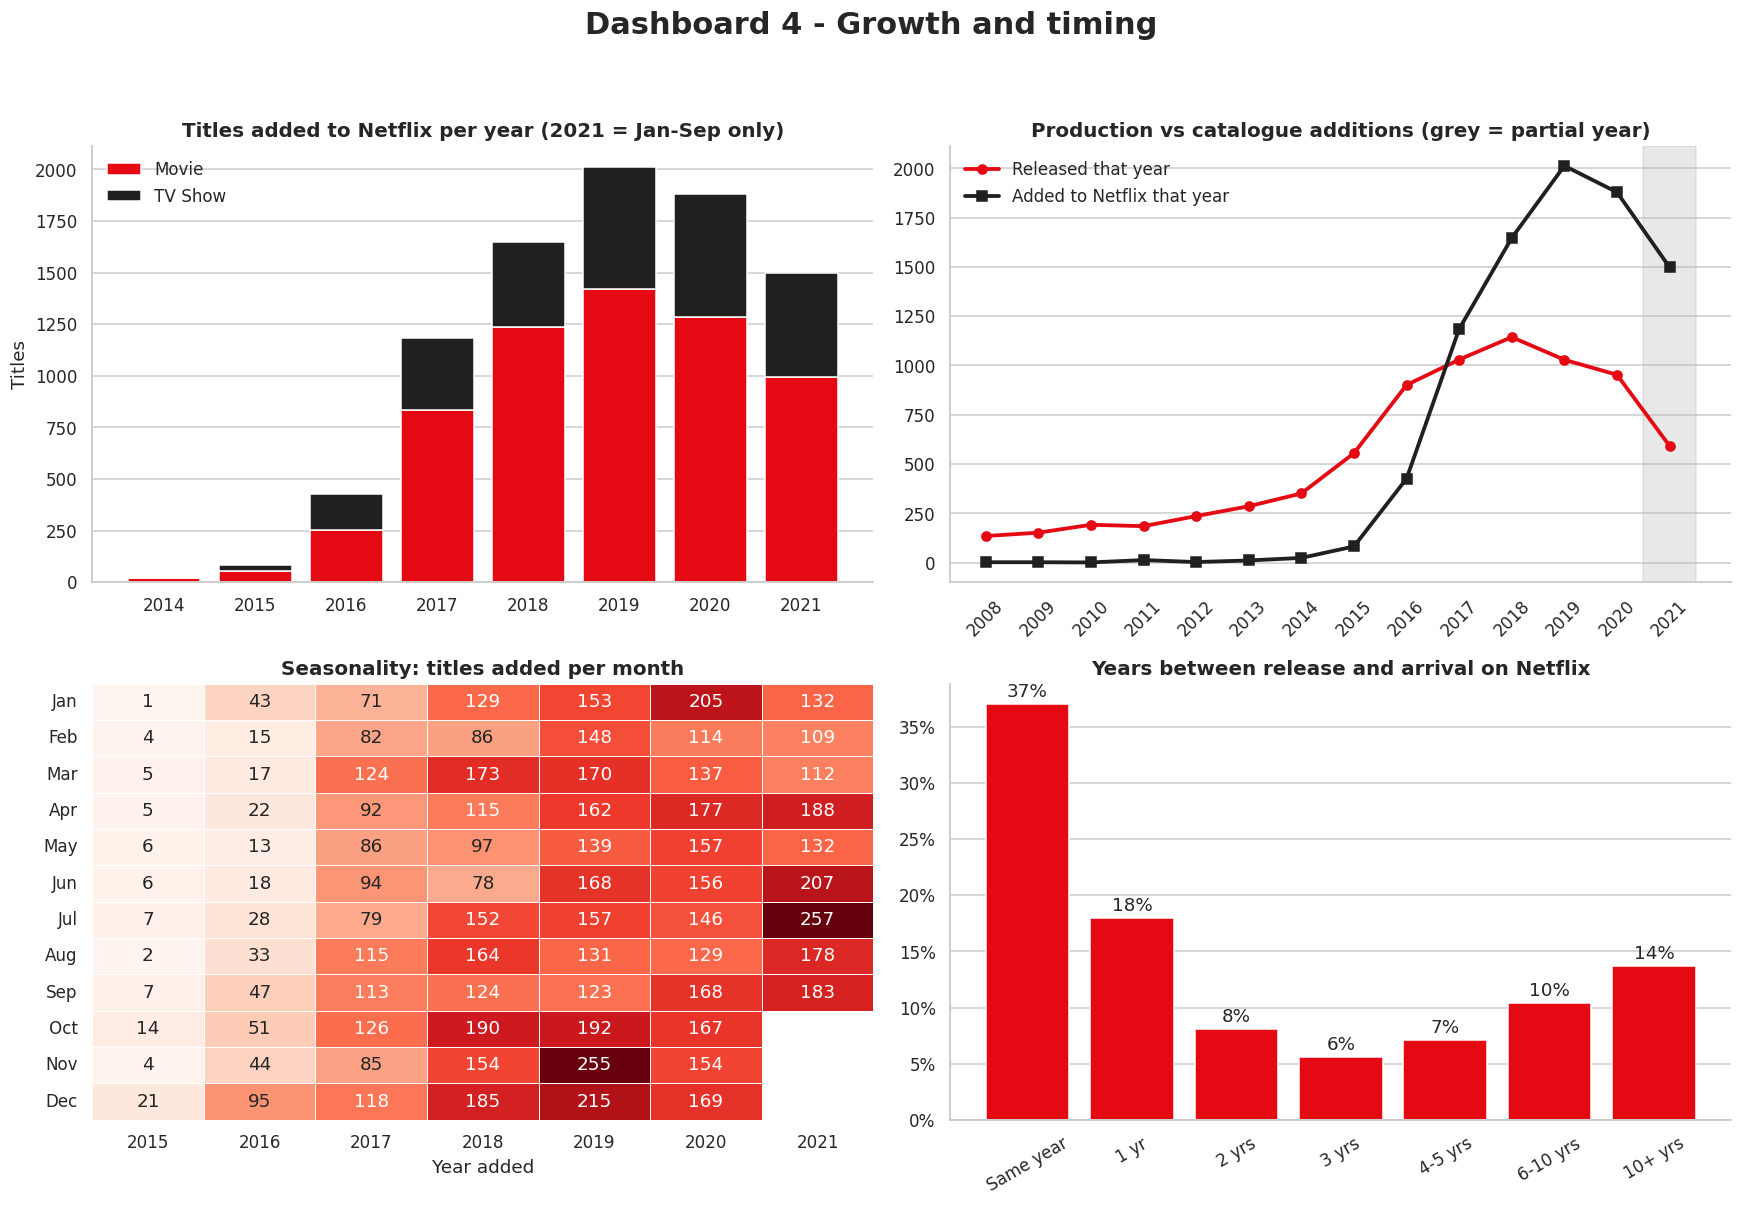

In [ ]:
lag_bins = pd.cut(df["lag_years"], bins=[-1, 0, 1, 2, 3, 5, 10, 200], labels=["Same year", "1 yr", "2 yrs", "3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"])
lag_share = lag_bins.value_counts(normalize=True).sort_index() * 100
added = df.groupby("year_added").size()
added_by_type = pd.crosstab(df["year_added"], df["type"])[["Movie", "TV Show"]].loc[2014:]
yrs = list(range(2008, PARTIAL_YEAR + 1))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].bar(added_by_type.index.astype(str), added_by_type["Movie"], color=NETFLIX_RED, label="Movie")
axes[0, 0].bar(added_by_type.index.astype(str), added_by_type["TV Show"], bottom=added_by_type["Movie"], color=NETFLIX_DARK, label="TV Show")
axes[0, 0].set_title(f"Titles added to Netflix per year ({PARTIAL_YEAR} = Jan-Sep only)"); axes[0, 0].legend(frameon=False); axes[0, 0].set_ylabel("Titles")

axes[0, 1].plot(yrs, [yearly["Total"].get(y, 0) for y in yrs], color=NETFLIX_RED, marker="o", linewidth=2.5, label="Released that year")
axes[0, 1].plot(yrs, [added.get(y, 0) for y in yrs], color=NETFLIX_DARK, marker="s", linewidth=2.5, label="Added to Netflix that year")
axes[0, 1].axvspan(PARTIAL_YEAR - 0.5, PARTIAL_YEAR + 0.5, color=GREY, alpha=0.3)
axes[0, 1].set_xticks(yrs); axes[0, 1].tick_params(axis="x", rotation=45); axes[0, 1].legend(frameon=False, loc="upper left")
axes[0, 1].set_title("Production vs catalogue additions (grey = partial year)")

sns.heatmap(season, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar=False, ax=axes[1, 0])
axes[1, 0].set_title("Seasonality: titles added per month"); axes[1, 0].set_xlabel("Year added"); axes[1, 0].set_ylabel(""); axes[1, 0].grid(False)
axes[1, 0].tick_params(axis="y", rotation=0)

bb = axes[1, 1].bar(lag_share.index.astype(str), lag_share.values, color=NETFLIX_RED)
axes[1, 1].bar_label(bb, fmt="%.0f%%", padding=2); axes[1, 1].tick_params(axis="x", rotation=30)
axes[1, 1].set_title("Years between release and arrival on Netflix"); axes[1, 1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

finish_dashboard(fig, "Dashboard 4 - Growth and timing", "04_dashboard_growth_timing")

---
## Step 4 – Generate actionable business insights
A good insight has three parts: **Finding** (what the data shows) → **Evidence** (the numbers) → **Recommended action** (what a business should do).
All numbers below are computed from the data.

In [ ]:
sc = scorecard
tv_share_2015 = yearly.loc[2015, "TV Show"] / yearly.loc[2015, "Total"] * 100
tv_share_last = yearly.loc[LAST_COMPLETE, "TV Show"] / yearly.loc[LAST_COMPLETE, "Total"] * 100
movie_chg = (yearly.loc[LAST_COMPLETE, "Movie"] / yearly.loc[2018, "Movie"] - 1) * 100
tv_chg = (yearly.loc[LAST_COMPLETE, "TV Show"] / yearly.loc[2018, "TV Show"] - 1) * 100

adult_2010, adult_last = mix_pct.loc[2010, "Adults"], mix_pct.loc[LAST_COMPLETE, "Adults"]
kids_only = (df["rating_group"] == "Kids").mean() * 100
kids_all = df["rating_group"].isin(["Kids", "Older Kids"]).mean() * 100

risers = momentum.tail(3).iloc[::-1]; fallers = momentum.head(3)
fmt_g = lambda d: ", ".join(f"{g} ({v:+.1f} pp)" for g, v in zip(d.index, d["change_pp"]))

busy = [calendar.month_name[m] for m in month_totals.sort_values(ascending=False).head(3).index]
quiet = [calendar.month_name[m] for m in month_totals.sort_values().head(3).index]
long_tail = int((country_counts["titles"] <= 5).sum())

insights = pd.DataFrame([
    {"Finding": f"Output peaked in {peak_year} and the mix is shifting from movies to TV.",
     "Evidence": f"Releases peaked at {int(yearly.loc[peak_year, 'Total']):,} titles in {peak_year}. From 2018 to {LAST_COMPLETE} movie releases changed by {movie_chg:+.0f}% while TV Show releases changed by {tv_chg:+.0f}%; TV's share of releases rose from {tv_share_2015:.0f}% (2015) to {tv_share_last:.0f}% ({LAST_COMPLETE}).",
     "Recommended action": "Weight incremental content investment towards series, which are growing, while keeping a smaller, higher-quality film slate."},
    {"Finding": "The catalogue keeps growing by leaning on older titles.",
     "Evidence": f"Titles added per month rose from {sc.loc['Titles added per month', early_label]:.0f} to {sc.loc['Titles added per month', recent_label]:.0f}, yet the share arriving within a year of release fell from {sc.loc['Arrived within 1 year of release (%)', early_label]:.0f}% to {sc.loc['Arrived within 1 year of release (%)', recent_label]:.0f}%.",
     "Recommended action": "Track the balance between fresh releases (which attract subscribers) and back-catalogue (which retains them), and plan licensing renewals accordingly."},
    {"Finding": "The US share of additions is growing while India's is shrinking, and the catalogue is geographically concentrated.",
     "Evidence": f"US share of known-country titles: {sc.loc['US share of known-country titles (%)', early_label]:.0f}% -> {sc.loc['US share of known-country titles (%)', recent_label]:.0f}%; India: {sc.loc['India share of known-country titles (%)', early_label]:.0f}% -> {sc.loc['India share of known-country titles (%)', recent_label]:.0f}%. The top 5 countries supply {country_counts['share_%'].head(5).sum():.0f}% of titles and {long_tail} of {len(country_counts)} countries have 5 titles or fewer.",
     "Recommended action": "Reduce dependence on a few markets: scale TV-led production hubs (e.g. South Korea, Japan, Taiwan) and grow local-language content in the long tail of under-served countries."},
    {"Finding": "Mature audiences dominate, and content for the youngest viewers is a small slice.",
     "Evidence": f"Adult-rated content rose from {adult_2010:.0f}% of 2010 releases to {adult_last:.0f}% of {LAST_COMPLETE} releases. Titles rated for young children (Kids) are only {kids_only:.0f}% of the catalogue ({kids_all:.0f}% including Older Kids).",
     "Recommended action": "Evaluate a family/kids programming push, using viewing-time data to test whether the gap is unmet demand or simply low demand."},
    {"Finding": f"The genre mix is shifting: {', '.join(risers.index)} are gaining share while {', '.join(fallers.index)} are losing it.",
     "Evidence": f"Gaining share: {fmt_g(risers)}. Losing share: {fmt_g(fallers)} (change in share of titles added, {early_label} vs {recent_label}).",
     "Recommended action": "Rebalance the slate towards the gaining genres, but validate with viewership data before reallocating budget (this dataset counts titles, not views)."},
    {"Finding": "Additions are seasonal.",
     "Evidence": f"Across 2016-{LAST_COMPLETE}, the busiest months for new additions were {', '.join(busy)}; the quietest were {', '.join(quiet)}.",
     "Recommended action": "Concentrate marketing around the busy Q4 window, and test counter-programming of flagship titles in the quieter months."},
    {"Finding": "Metadata gaps limit deeper analysis.",
     "Evidence": f"{unknown_director:.0f}% of titles have no director and {unknown_country:.0f}% have no country recorded.",
     "Recommended action": "Improve metadata capture (director, country, cast) so future analyses can cover talent and regional performance."},
])
insights.index = insights.index + 1
insights.index.name = "#"

insights.to_csv(OUT_DIR / "business_insights.csv")
pd.set_option("display.max_colwidth", None)
insights

,Finding,Evidence,Recommended action
#,,,
1,Output peaked in 2018 and the mix is shifting from movies to TV.,"Releases peaked at 1,144 titles in 2018. From 2018 to 2020 movie releases changed by -33% while TV Show releases changed by +15%; TV's share of releases rose from 29% (2015) to 46% (2020).","Weight incremental content investment towards series, which are growing, while keeping a smaller, higher-quality film slate."
2,The catalogue keeps growing by leaning on older titles.,"Titles added per month rose from 90 to 163, yet the share arriving within a year of release fell from 58% to 53%.","Track the balance between fresh releases (which attract subscribers) and back-catalogue (which retains them), and plan licensing renewals accordingly."
3,"The US share of additions is growing while India's is shrinking, and the catalogue is geographically concentrated.",US share of known-country titles: 34% -> 40%; India: 16% -> 11%. The top 5 countries supply 66% of titles and 32 of 84 countries have 5 titles or fewer.,"Reduce dependence on a few markets: scale TV-led production hubs (e.g. South Korea, Japan, Taiwan) and grow local-language content in the long tail of under-served countries."
4,"Mature audiences dominate, and content for the youngest viewers is a small slice.",Adult-rated content rose from 35% of 2010 releases to 54% of 2020 releases. Titles rated for young children (Kids) are only 6% of the catalogue (23% including Older Kids).,"Evaluate a family/kids programming push, using viewing-time data to test whether the gap is unmet demand or simply low demand."
5,"The genre mix is shifting: Comedies, Romantic Movies, Children & Family Movies are gaining share while Documentaries, International Movies, Stand-Up Comedy are losing it.","Gaining share: Comedies (+5.0 pp), Romantic Movies (+2.6 pp), Children & Family Movies (+2.5 pp). Losing share: Documentaries (-6.0 pp), International Movies (-5.6 pp), Stand-Up Comedy (-3.4 pp) (change in share of titles added, 2016-2018 vs 2019-21 (YTD)).","Rebalance the slate towards the gaining genres, but validate with viewership data before reallocating budget (this dataset counts titles, not views)."
6,Additions are seasonal.,"Across 2016-2020, the busiest months for new additions were December, October, November; the quietest were February, May, June.","Concentrate marketing around the busy Q4 window, and test counter-programming of flagship titles in the quieter months."
7,Metadata gaps limit deeper analysis.,29% of titles have no director and 3% have no country recorded.,"Improve metadata capture (director, country, cast) so future analyses can cover talent and regional performance."


> ⚠️ **Limitations to state in your report:** (1) the data is a catalogue snapshot to **Sept 2021** and counts *titles*, not viewing hours or revenue;
> (2) it cannot distinguish Netflix Originals from licensed content; (3) `country` is the production country, not availability;
> (4) the "why" behind each trend (e.g. COVID-19, strategy shifts) is a hypothesis, not something the data proves.

---
## Step 5 – Prepare and present the final analytical report
We assemble everything into **one self-contained HTML file** (charts are embedded, so you can email it or open it anywhere).
To get a PDF: open the HTML in your browser → *Print* → *Save as PDF*.

In [ ]:
def img_tag(name, alt):
    b64 = base64.b64encode((OUT_DIR / f"{name}.png").read_bytes()).decode()
    return f'<img src="data:image/png;base64,{b64}" alt="{alt}">'

headline = [
    f"The catalogue holds {len(df):,} titles ({(df['type'] == 'Movie').mean():.0%} movies, {(df['type'] == 'TV Show').mean():.0%} TV shows) from {known_country['country'].nunique()} countries.",
    f"New releases peaked in {peak_year}; since then movies have fallen while TV shows keep growing (TV is {tv_share_last:.0f}% of {LAST_COMPLETE} releases).",
    f"The catalogue is concentrated: the {country_counts['country'].iloc[0]} supplies {country_counts['share_%'].iloc[0]:.0f}% of titles and the top 5 countries {country_counts['share_%'].head(5).sum():.0f}%.",
    f"Content skews mature: {(df['rating_group'] == 'Adults').mean():.0%} of titles are Adult-rated and only {df['rating_group'].isin(['Kids', 'Older Kids']).mean():.0%} target Kids/Older Kids.",
    f"Growth in additions is increasingly driven by older titles; the share arriving within a year of release fell from {sc.loc['Arrived within 1 year of release (%)', early_label]:.0f}% to {sc.loc['Arrived within 1 year of release (%)', recent_label]:.0f}%.",
]

CSS = """
body{font-family:Segoe UI,Helvetica,Arial,sans-serif;color:#221F1F;max-width:1100px;margin:0 auto;padding:32px;line-height:1.55}
h1{color:#E50914;margin-bottom:0} h2{border-bottom:3px solid #E50914;padding-bottom:4px;margin-top:40px}
.sub{color:#666;margin-top:4px}
.kpis{display:flex;flex-wrap:wrap;gap:14px;margin:24px 0}
.kpi{flex:1 1 150px;background:#f6f6f6;border-left:5px solid #E50914;padding:12px 16px;border-radius:4px}
.kpi b{display:block;font-size:26px;color:#E50914}
img{max-width:100%;border:1px solid #ddd;border-radius:4px;margin:8px 0 22px}
table{border-collapse:collapse;width:100%;font-size:14px} th{background:#221F1F;color:#fff;text-align:left}
th,td{padding:8px 10px;border:1px solid #ddd;vertical-align:top} tr:nth-child(even){background:#fafafa}
.note{background:#fff7e6;border-left:5px solid #F6AE2D;padding:10px 16px;border-radius:4px}
"""

kpi_html = "".join(f'<div class="kpi"><b>{html_lib.escape(v)}</b>{html_lib.escape(l)}</div>' for v, l in kpis)
summary_html = "".join(f"<li>{html_lib.escape(h)}</li>" for h in headline)
insights_html = insights.reset_index().to_html(index=False, escape=True, border=0)
scorecard_html = scorecard.reset_index().rename(columns={"index": "Metric"}).to_html(index=False, border=0)

report = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><title>Netflix Business Insights Report</title><style>{CSS}</style></head><body>
<h1>Netflix Business Insights Report</h1>
<p class="sub">Analysis of the Netflix catalogue (titles added {df['date_added'].min().year}-{PARTIAL_YEAR}, data to {df['date_added'].max():%B %Y}) &middot; Prepared {pd.Timestamp.today():%d %B %Y}</p>
<div class="kpis">{kpi_html}</div>

<h2>1. Executive summary</h2><ul>{summary_html}</ul>

<h2>2. Dashboards</h2>
<h3>Catalogue overview</h3>{img_tag("01_dashboard_catalogue_overview", "Catalogue overview dashboard")}
<h3>Geography</h3>{img_tag("02_dashboard_geography", "Geography dashboard")}
<h3>Audience and genre</h3>{img_tag("03_dashboard_audience_genre", "Audience and genre dashboard")}
<h3>Growth and timing</h3>{img_tag("04_dashboard_growth_timing", "Growth and timing dashboard")}

<h2>3. Business insights and recommendations</h2>{insights_html}

<h2>4. Trend scorecard</h2>
<p>Comparison of titles added in {early_label} vs {recent_label}.</p>{scorecard_html}

<h2>5. Method and limitations</h2>
<p>The raw file was cleaned in Task 1 (hidden placeholders converted to missing values, duplicates removed, dates and durations parsed, ratings and countries standardised).
Analysis used Python (pandas, matplotlib, seaborn).</p>
<div class="note"><b>Limitations.</b> The data is a catalogue snapshot to {df['date_added'].max():%B %Y} and counts titles, not viewing or revenue. It cannot separate Netflix Originals from licensed titles,
and the explanations for trends (e.g. COVID-19, strategy changes) are hypotheses rather than findings.</div>
</body></html>"""

REPORT_PATH = OUT_DIR / "Netflix_Business_Insights_Report.html"
REPORT_PATH.write_text(report, encoding="utf-8")
print(f"Report saved: {REPORT_PATH.resolve()}  ({REPORT_PATH.stat().st_size / 1024:.0f} KB)")
print("Open it in your browser (double-click the file). To make a PDF: Print -> Save as PDF.")

Report saved: /content/drive/MyDrive/Netflix_Analysis/outputs/task6_business_report/Netflix_Business_Insights_Report.html  (1602 KB)
Open it in your browser (double-click the file). To make a PDF: Print -> Save as PDF.


### How to present it (suggested 6-slide / 5-minute structure)
1. **Context & data** – what the dataset is, its limits (Sept 2021 snapshot).
2. **Catalogue at a glance** – Dashboard 1.
3. **Where content comes from** – Dashboard 2.
4. **Who it is for & what genres** – Dashboard 3.
5. **How it is growing** – Dashboard 4.
6. **Recommendations** – the 3 strongest rows of the insight table, plus limitations.

---
## ✅ Summary
Performed a full EDA (including outlier and correlation checks), quantified trends with a before/after scorecard and genre momentum, built four themed dashboards,
converted the findings into *Finding → Evidence → Action* insights, and generated a shareable HTML report in `outputs/task6_business_report/`.